In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py

In [3]:
df_props = pd.read_csv("host_props.csv")

In [4]:
list_of_CIDs = []
with h5py.File("/Volumes/S-Express/TITAN/SN_age_samples.h5", "r") as f:
    keys = list(f.keys())
    first = f[keys[0]]
    list_of_age_samples = np.empty((len(keys),) + first.shape, dtype=np.float32)
    for i, key in enumerate(keys):
        list_of_CIDs.append(key)
        f[key].read_direct(list_of_age_samples[i])

In [5]:
list_of_age_samples.shape

(9361, 1000, 100)

In [6]:
df_props.columns

Index(['transient', 'stellar_mass_16', 'stellar_mass_50', 'stellar_mass_84',
       'sfr_16', 'sfr_50', 'sfr_84', 'ssfr_16', 'ssfr_50', 'ssfr_84',
       'iyer2019:metallicity_16', 'iyer2019:metallicity_50',
       'iyer2019:metallicity_84', 'mass_weighted_age_16',
       'mass_weighted_age_50', 'mass_weighted_age_84', 'dust:Av_16',
       'dust:Av_50', 'dust:Av_84', 'uv_colour_16', 'uv_colour_50',
       'uv_colour_84', 'vj_colour_16', 'vj_colour_50', 'vj_colour_84',
       'gz_colour_16', 'gz_colour_50', 'gz_colour_84', 'ps_g_mag_16',
       'ps_g_mag_50', 'ps_g_mag_84', 'ps_r_mag_16', 'ps_r_mag_50',
       'ps_r_mag_84', 'ps_i_mag_16', 'ps_i_mag_50', 'ps_i_mag_84',
       'ps_z_mag_16', 'ps_z_mag_50', 'ps_z_mag_84', 'ps_y_mag_16',
       'ps_y_mag_50', 'ps_y_mag_84', 'sdss_u_mag_16', 'sdss_u_mag_50',
       'sdss_u_mag_84', 'sdss_g_mag_16', 'sdss_g_mag_50', 'sdss_g_mag_84',
       'sdss_r_mag_16', 'sdss_r_mag_50', 'sdss_r_mag_84', 'sdss_i_mag_16',
       'sdss_i_mag_50', 'sdss_i_mag

In [1]:
df_props

NameError: name 'df_props' is not defined

In [5]:
from extinction import fitzpatrick99
# central wavelengths of SDSS u and r bands
lambda_u = 3543.0
lambda_r = 6231.0

# compute extinction in u and r bands
A_u = fitzpatrick99(np.array([lambda_u]), a_v=1, r_v=3.1)  # A_lambda / A_V for R_V=3.1
A_r = fitzpatrick99(np.array([lambda_r]), a_v=1, r_v=3.1)  # A_lambda / A_V for R_V=3.1

# compute color excess per AV for u-r
E_u_r_per_AV = A_u - A_r
E_u_r_per_AV

array([0.74254586])

In [6]:
df_props['u-r'] = df_props['sdss_u_mag_50'] - df_props['sdss_r_mag_50']
df_props['u-r_nodust'] = df_props['sdss_u_mag_50'] - df_props['sdss_r_mag_50']
df_props['u-r_nodust'] -= E_u_r_per_AV * df_props['dust:Av_50']

lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-10.5) & df_props['u-r'].gt(1.9)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5) & df_props['u-r'].le(1.6)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-10.5) & df_props['u-r'].gt(1.9)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5) & df_props['u-r'].le(1.6)

names = [ "lowmass_SF", "highmass_Q", "highmass_SF","lowmass_Q",]
colors = ['royalblue','firebrick','yellowgreen','orange',]
masks = [lowmass_SF, highmass_Q, highmass_SF, lowmass_Q]

In [82]:
0.84 - 0.026*13.5

0.489

(np.float64(-0.08856320316270173), np.float64(1.8598272664167363))

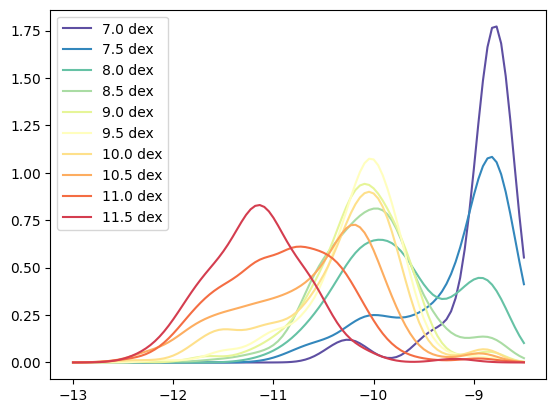

In [7]:
from scipy.stats import gaussian_kde
mass_locs = np.arange(7,12,0.5)
for mass_loc in mass_locs:
    mask = df_props['stellar_mass_50'].between(mass_loc-0.25, mass_loc+0.25)
    _kde = gaussian_kde(df_props['ssfr_50'][mask])
    x = np.linspace(-13, -8.5, 100)
    plt.plot(x, _kde(x), color=plt.cm.Spectral_r((mass_loc-7)/5), label=f'{mass_loc:.1f} dex')
plt.legend()
    # plt.hist(df_props['ssfr_50'][mask], bins=30, alpha=1, label=f'{mass_loc:.1f} dex',
    #          color=plt.cm.Spectral_r((mass_loc-7)/5),histtype='step',lw=2,density=True)
# plt.axvline(1.6)
# plt.axvline(1.9)
plt.ylim()

(np.float64(-0.1062653470693295), np.float64(2.231572288455919))

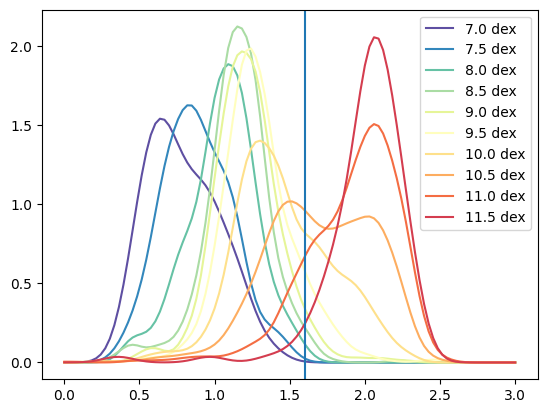

In [8]:
from scipy.stats import gaussian_kde
mass_locs = np.arange(7,12,0.5)
for mass_loc in mass_locs:
    mask = df_props['stellar_mass_50'].between(mass_loc-0.25, mass_loc+0.25)
    _kde = gaussian_kde(df_props['u-r_nodust'][mask])
    x = np.linspace(0, 3, 100)
    plt.plot(x, _kde(x), color=plt.cm.Spectral_r((mass_loc-7)/5), label=f'{mass_loc:.1f} dex')
plt.legend()
    # plt.hist(df_props['ssfr_50'][mask], bins=30, alpha=1, label=f'{mass_loc:.1f} dex',
    #          color=plt.cm.Spectral_r((mass_loc-7)/5),histtype='step',lw=2,density=True)
# plt.axvline(1.6)
plt.axvline(1.6)
plt.ylim()

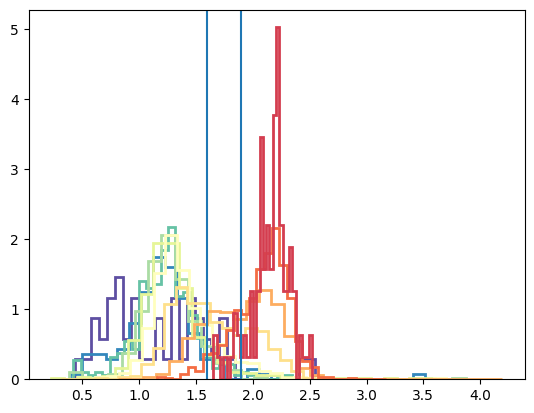

In [130]:
mass_locs = np.arange(7,12,0.5)
for mass_loc in mass_locs:
    mask = df_props['stellar_mass_50'].between(mass_loc-0.25, mass_loc+0.25)
    plt.hist(df_props['u-r'][mask], bins=30, alpha=1, label=f'{mass_loc:.1f} dex',
             color=plt.cm.Spectral_r((mass_loc-7)/5),histtype='step',lw=2,density=True)
plt.axvline(1.6)
plt.axvline(1.9)

# df_props['u-r'].hist(bins=)

(7.0, 12.0)

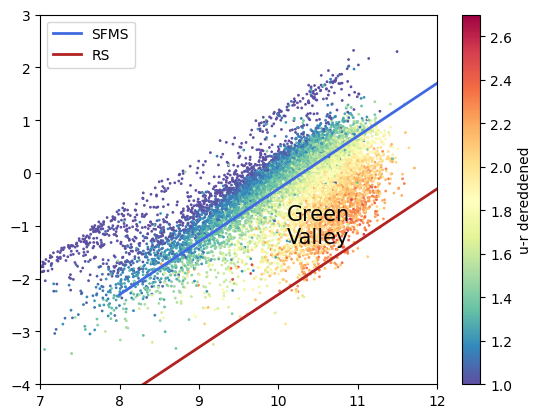

In [182]:
SFMS = lambda logmass: logmass-10.3#
Q_cut = lambda logmass: logmass-11
# SFMS = lambda logmass: (0.84 - 0.026*13.5) * logmass -#- (6.51 - 0.11*13.5)

mass_grid = np.linspace(8,12,100)

# plt.hist2d(df_props['stellar_mass_50'],np.log10(df_props['sfr_50']),bins=100,cmap='BuGn',vmax=20)#,c='k',s=1,alpha=0.5);
sc = plt.scatter(df_props['stellar_mass_50'],np.log10(df_props['sfr_50']),
           c=df_props['u-r_nodust'],vmin=1.0, vmax=2.7,s=1,cmap='Spectral_r')#,c='k',s=1,alpha=0.5);
plt.colorbar(sc, label='u-r dereddened')
plt.plot(mass_grid, SFMS(mass_grid), c='royalblue', lw=2,label='SFMS')   
plt.text(10.5,-1.,'Green\nValley',color='k',fontsize=15,ha='center',va='center')
plt.plot(mass_grid, mass_grid-12.3, c='firebrick', lw=2,label='RS')
plt.legend()
plt.ylim(-4,3)
plt.xlim(7,12)

Text(0, 0.5, 'log sSFR')

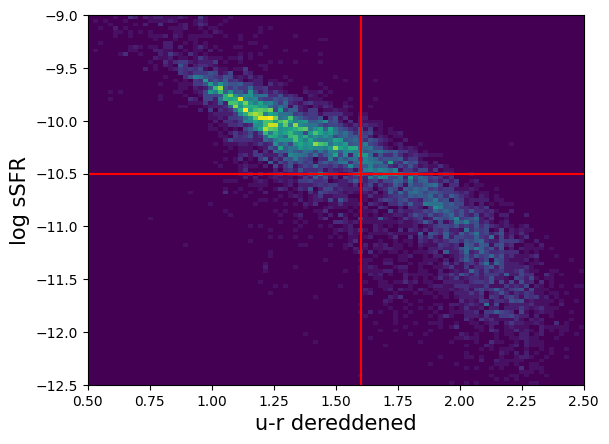

In [174]:
plt.hist2d(df_props['u-r_nodust'], df_props['ssfr_50'],bins=[np.linspace(0.5,2.5,100),np.linspace(-12.5,-9,100)]);
plt.axhline(-10.5,c='r')
plt.axvline(1.6,c='r')
plt.xlabel('u-r dereddened', fontsize=15)
plt.ylabel('log sSFR', fontsize=15)
# plt.xlim(0.5,2.8)

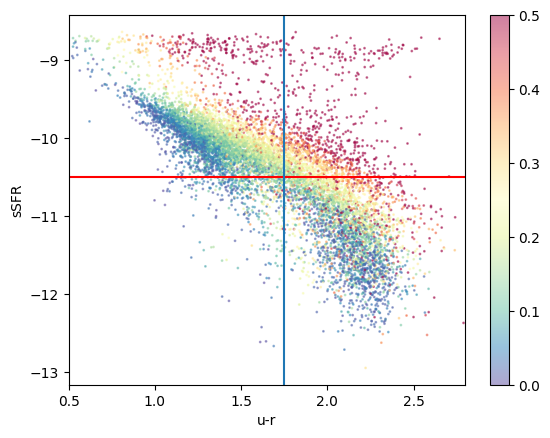

In [160]:
sc = plt.scatter(df_props['u-r'], df_props['ssfr_50'], c=df_props['dust:Av_50'], s=1, alpha=0.5,
            vmin=0,vmax=0.5,cmap='Spectral_r')
plt.colorbar(sc)
plt.xlabel('u-r')
plt.ylabel('sSFR')
plt.xlim(0.5,2.8)
plt.axhline(-10.5,c='r')
plt.axvline(1.75)

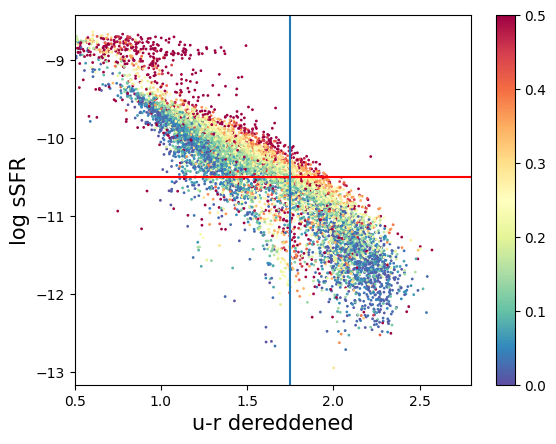

In [173]:
sc = plt.scatter(df_props['u-r_nodust'], df_props['ssfr_50'], c=df_props['dust:Av_50'], s=1, alpha=1,
            vmin=0,vmax=0.5,cmap='Spectral_r')
plt.colorbar(sc)
plt.xlabel('u-r dereddened', fontsize=15)
plt.ylabel('log sSFR', fontsize=15)
plt.xlim(0.5,2.8)
plt.axhline(-10.5,c='r')
plt.axvline(1.75)

In [ ]:
plt.hist()

In [39]:
for i in df_props.index.values:
    CID = df_props['transient'][i]
    prog_age = np.median(list_of_age_samples[list_of_CIDs.index(CID)].mean(axis=1))
    df_props.loc[i, 'prog_age'] = prog_age


In [16]:
df_props['u-r'] = df_props['sdss_u_mag_50'] - df_props['sdss_r_mag_50']
df_props['u-r_nodust'] = df_props['sdss_u_mag_50'] - df_props['sdss_r_mag_50']
df_props['u-r_nodust'] -= E_u_r_per_AV * df_props['dust:Av_50']

lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-10.5) #& df_props['u-r_nodust'].gt(1.75)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5) #& df_props['u-r_nodust'].le(1.75)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-10.5) #& df_props['u-r_nodust'].gt(1.75)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5) #& df_props['u-r_nodust'].le(1.75)
names = ["lowmass_Q", "lowmass_SF", "highmass_Q", "highmass_SF"]
colors = ['orange','royalblue','firebrick','yellowgreen']
masks = [lowmass_Q, lowmass_SF, highmass_Q, highmass_SF]

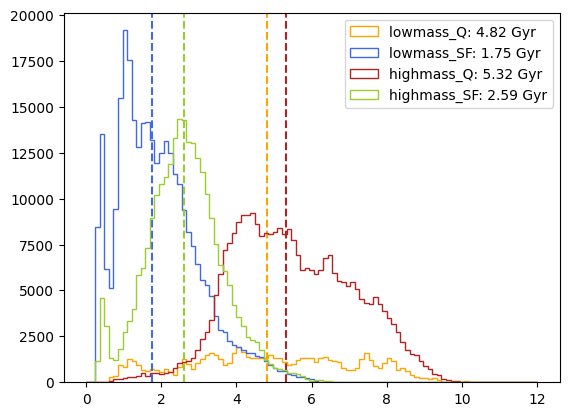

In [17]:
bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask].mean(axis=1)
    
    plt.hist(np.ravel(_sample_means), bins=bins, 
             color=color, histtype='step', label=name+f': {np.median(_sample_means):.2f} Gyr');
    plt.axvline(np.median(_sample_means), color=color, linestyle='--')
plt.legend();

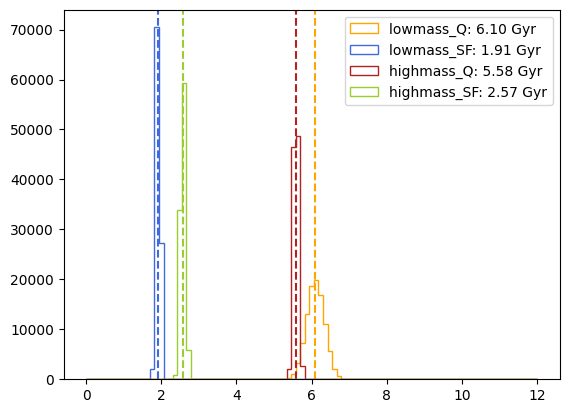

In [13]:
bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask].mean(axis=0)
    
    plt.hist(np.ravel(_sample_means), bins=bins, 
             color=color, histtype='step', label=name+f': {np.median(_sample_means):.2f} Gyr');
    plt.axvline(np.median(_sample_means), color=color, linestyle='--')
plt.legend();

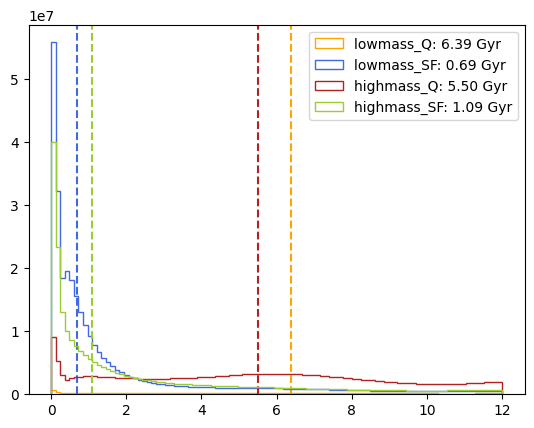

In [14]:
bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask]#.mean(axis=0)
    
    plt.hist(np.ravel(_sample_means), bins=bins, 
             color=color, histtype='step', label=name+f': {np.median(_sample_means):.2f} Gyr');
    plt.axvline(np.median(_sample_means), color=color, linestyle='--')
plt.legend();

## galaxy age vs. t_prog

In [10]:
# compute mean expectation value of age samples and add to df_props
for CID, age in zip(list_of_CIDs, np.median(list_of_age_samples.mean(axis=1),axis=1)):
    df_props.loc[df_props['transient'] == CID, 'prog_age'] = np.median(age)

/var/folders/hf/dh49zz3n1x5d1p_b4qn8g4z00000gn/T/ipykernel_53845/1631050479.py:24: UserWarning: You passed a edgecolor/edgecolors ('orange') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(df_props['mass_weighted_age_50'][mask], df_props['prog_age'][mask], s=ms,
/var/folders/hf/dh49zz3n1x5d1p_b4qn8g4z00000gn/T/ipykernel_53845/1631050479.py:26: UserWarning: You passed a edgecolor/edgecolors ('orange') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax_bot.scatter(df_props['mass_weighted_age_50'][mask],


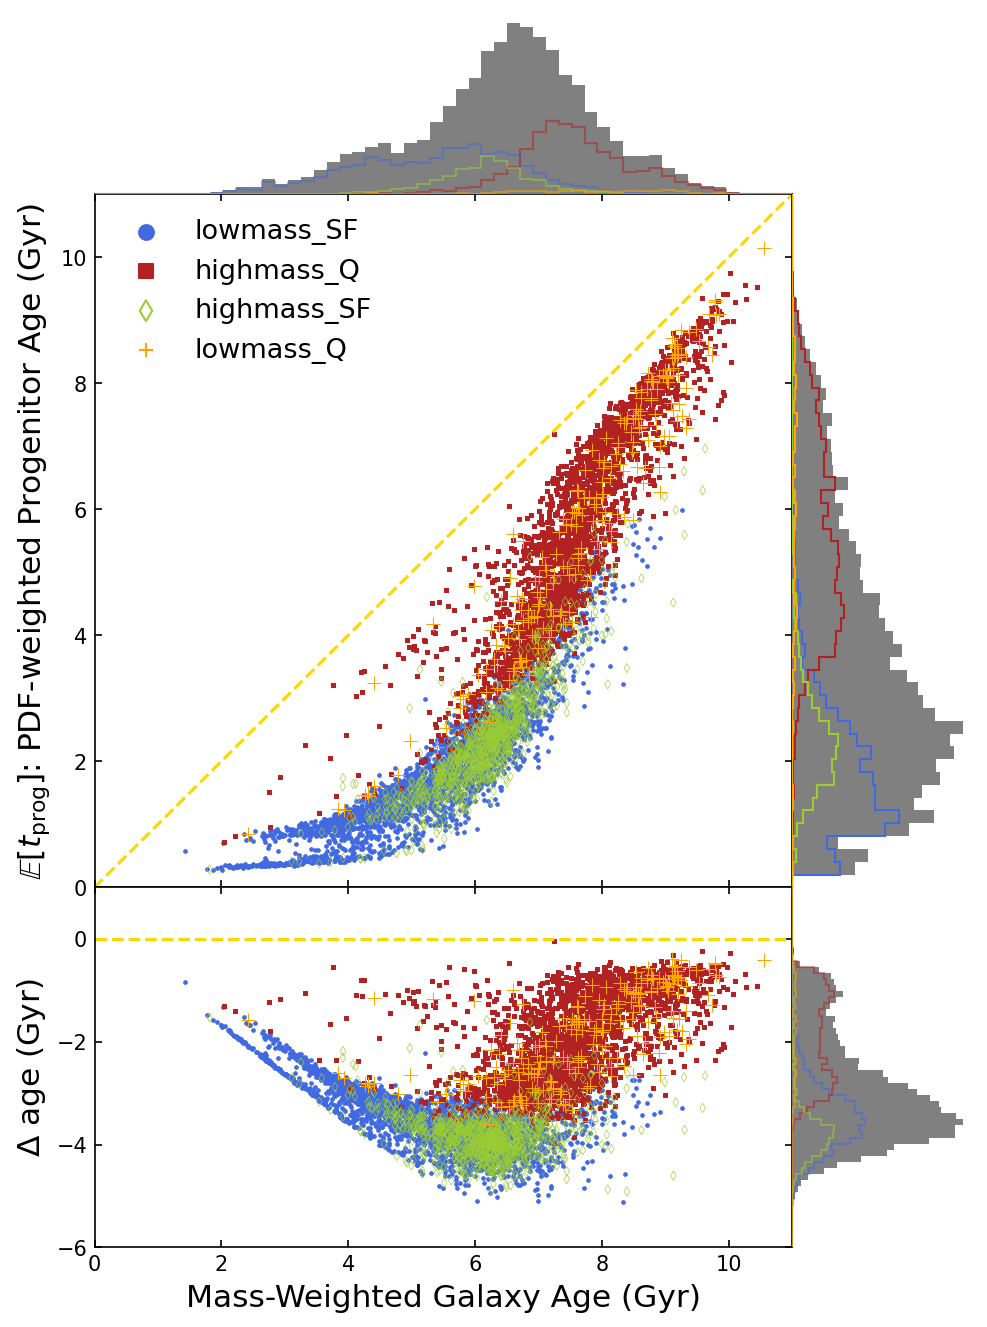

In [11]:
df_props['age_diff'] = df_props['prog_age'] - df_props['mass_weighted_age_50']

fig,ax = plt.subplots(1,1,figsize=(6,6),dpi=150)
pos = ax.get_position().bounds
ax_bot = fig.add_axes([pos[0], pos[1]-0.4, pos[2], 0.4])
ax_top = fig.add_axes([pos[0], pos[1]+pos[3], pos[2], 0.2])
ax_right = fig.add_axes([pos[0]+pos[2], pos[1], 0.2, pos[3]])
ax_botright = fig.add_axes([pos[0]+pos[2], pos[1]-0.4, 0.2, 0.4])


# histograms
age_bins = np.linspace(0,12,60)
diff_bins = np.linspace(-6,1,60)
ax_right.hist(df_props['prog_age'], bins=age_bins, orientation='horizontal', color='gray')
ax_top.hist(df_props['mass_weighted_age_50'], bins=age_bins, color='gray')
ax_botright.hist(df_props['age_diff'], bins=diff_bins, color='gray',orientation='horizontal')

for mask, name, color,marker,ms,noFC,lw in zip(
    masks, names, colors, 
    ['o','s','d','+'], 
    [3,3,10,50],
    [False,False,True,False],
    [0.5,0.5,0.3,0.5]):
    ax.scatter(df_props['mass_weighted_age_50'][mask], df_props['prog_age'][mask], s=ms, 
                alpha=1, label=name, ec=color, fc='none' if noFC else color, marker=marker, lw=lw)
    ax_bot.scatter(df_props['mass_weighted_age_50'][mask], 
                   df_props['age_diff'][mask], s=ms,
                alpha=1, label=name, ec=color, fc='none' if noFC else color, marker=marker, lw=lw)
    
    # add histograms of each population to the marginal axes
    ax_right.hist(df_props['prog_age'][mask], bins=age_bins, orientation='horizontal', color=color, histtype='step')
    ax_top.hist(df_props['mass_weighted_age_50'][mask], bins=age_bins, color=color, alpha=0.5, histtype='step')
    ax_botright.hist(df_props['age_diff'][mask], bins=diff_bins, color=color, alpha=0.5, orientation='horizontal', histtype='step')
    
    
leg = ax.legend(frameon=False, fontsize=13)
# set marker size in legend
for handle in leg.legend_handles:
    handle.set_sizes([50])
    handle.set_linewidth(1)

ax.set_ylabel(r'$\mathbb{E}[t_\mathrm{prog}]$: PDF-weighted Progenitor Age (Gyr)', fontsize=15)
ax_bot.set_xlabel('Mass-Weighted Galaxy Age (Gyr)', fontsize=15)
ax_bot.set_ylabel(r'$\Delta$ age (Gyr)', fontsize=15)
ax.plot([0,12],[0,12],c='gold',ls='--')
ax.set_ylim(0,11)
ax.set_xlim(0,11)
ax.tick_params(direction='in', top=True, right=True)
ax.set_xticklabels([])


ax_top.axis('off')
ax_right.axis('off')
ax_botright.axis('off')
ax_top.set_xlim(ax.get_xlim())
ax_right.set_ylim(ax.get_ylim())
ax_bot.set_xlim(ax.get_xlim())
ax_bot.set_ylim(-6,1)
ax_botright.set_ylim(-6,1)
ax_bot.set_yticks(np.arange(-6,1,2))
ax_bot.tick_params(direction='in', top=True, right=True)
ax_bot.axhline(0, c='gold', ls='--')
# plt.scatter(df_props['prog_age'], df_props['mass_weighted_age_50'], s=1, alpha=0.5,)

In [81]:
df_props.sort_values('age_diff').head(30)[['transient','prog_age','mass_weighted_age_50','age_diff','ssfr_50']].to_csv('age_diff_top30.csv', index=False)

## histograms

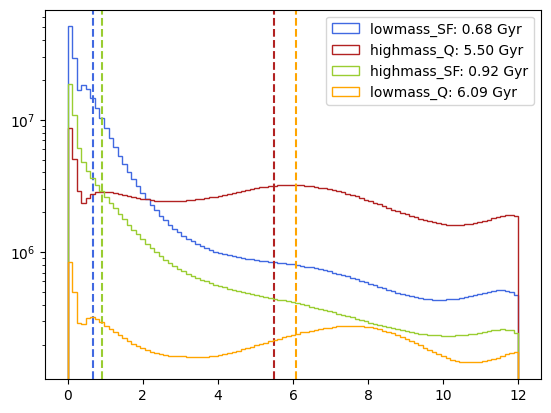

In [12]:
# 
bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask]#.mean(axis=0)
    
    plt.hist(np.ravel(_sample_means), bins=bins, 
             color=color, histtype='step', label=name+f': {np.median(_sample_means):.2f} Gyr');
    plt.axvline(np.median(_sample_means), color=color, linestyle='--')
plt.yscale('log')
plt.legend();

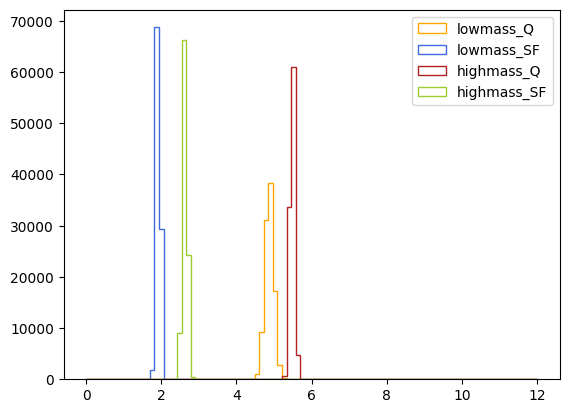

In [ ]:
bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask].mean(axis=0)
    
    
    plt.hist(np.ravel(_sample.mean(axis=0)), bins=bins, 
             color=color, histtype='step', label=name);
plt.legend();

(array([5.97630631e-01, 2.46427418e-01, 1.59284420e-01, 1.11555241e-01,
        8.48625744e-02, 6.95801556e-02, 6.10325464e-02, 5.64825860e-02,
        5.44251331e-02, 5.40075277e-02, 5.45663910e-02, 5.53969399e-02,
        5.58521249e-02, 5.54997452e-02, 5.41469365e-02, 5.18407632e-02,
        4.88007166e-02, 4.50153118e-02, 4.09347289e-02, 3.69865906e-02,
        3.35704415e-02, 3.09718863e-02, 2.95460457e-02, 2.95054708e-02,
        3.07943127e-02, 3.28419426e-02, 3.32157308e-02, 2.31656830e-02,
        6.70211033e-03, 2.98415691e-04]),
 array([ 0.04     ,  0.4854461,  0.9308922,  1.3763383,  1.8217844,
         2.2672305,  2.7126766,  3.1581227,  3.6035688,  4.0490149,
         4.494461 ,  4.9399071,  5.3853532,  5.8307993,  6.2762454,
         6.7216915,  7.1671376,  7.6125837,  8.0580298,  8.5034759,
         8.948922 ,  9.3943681,  9.8398142, 10.2852603, 10.7307064,
        11.1761525, 11.6215986, 12.0670447, 12.5124908, 12.9579369,
        13.403383 ]),
 <BarContainer object of

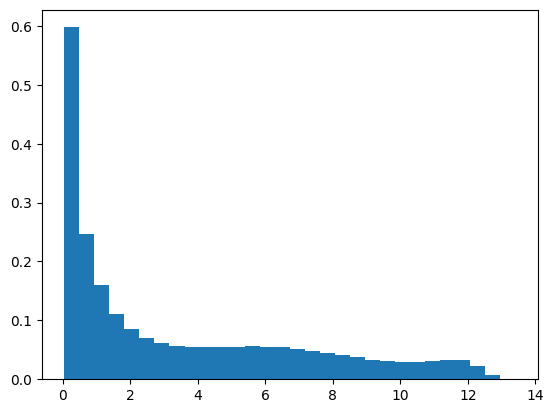

In [4]:
plt.hist(np.ravel(list_of_age_samples), bins=30, density=True)

## galaxy zoo

In [14]:
df_gz = pd.read_csv('titan_galaxy_zoo_crossmatch.csv')
df_gz = df_gz.rename(columns={'objname':'transient'})
df_merged = df_props.merge(df_gz[['transient','SFSM','SFFDF','SAYes']], on='transient', how='left')

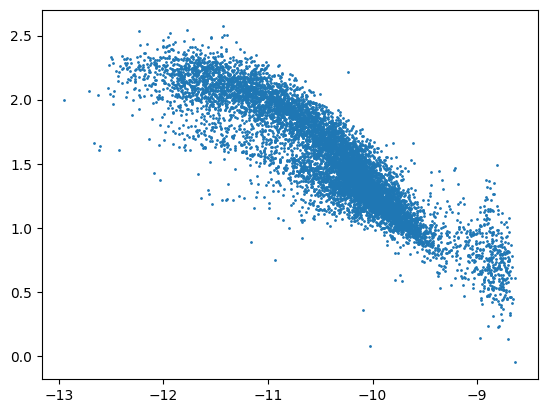

In [17]:
plt.scatter(df_merged['ssfr_50'],df_merged['u-r_nodust'],s=1)

Text(0.5, 0, 'log Stellar Mass')

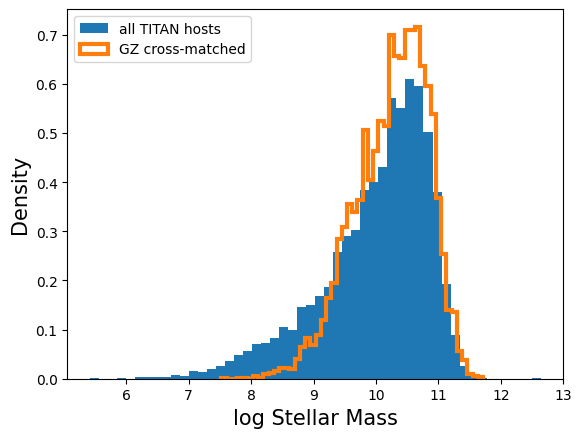

In [18]:

plt.hist(df_merged['stellar_mass_50'],bins=50,label='all TITAN hosts',density=True)
plt.hist(df_merged[df_merged['SFFDF'].notna()]['stellar_mass_50'],bins=50,
         label='GZ cross-matched',density=True,histtype='step',lw=3)
plt.legend()
plt.ylabel('Density', fontsize=15   )
plt.xlabel('log Stellar Mass', fontsize=15)

In [13]:
mask_disk = df_merged['SFFDF'].ge(0.8)
mask_smooth= df_merged['SFFDF'].le(0.2)
plt.hist(df_merged[mask_disk]['ssfr_50'],bins=50,label='Disk dominated',density=True,histtype='step',lw=3)
plt.hist(df_merged[mask_smooth]['ssfr_50'],bins=50,label='Smooth dominated',density=True,histtype='step',lw=3)
plt.legend()
plt.ylabel('Density', fontsize=15)
plt.xlabel('log sSFR', fontsize=15)

NameError: name 'df_merged' is not defined

Text(0.5, 0, 'log sSFR')

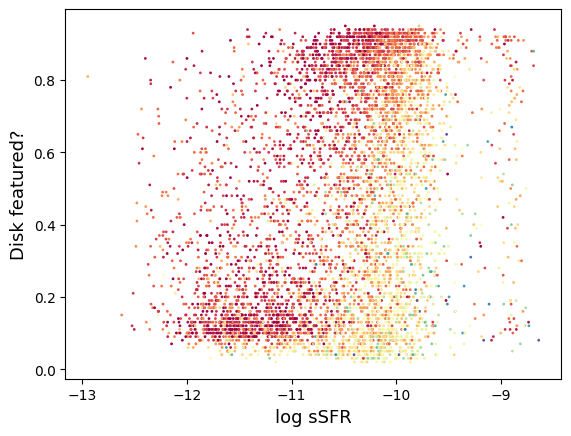

In [121]:
# df_merged.loc[df_merged['SAYes'].isna(), 'SAYes'] = -1
plt.scatter(df_merged['ssfr_50'], df_merged['SFFDF'],s=1,
            c=df_merged['stellar_mass_50'],vmin=8, vmax=11,cmap='Spectral_r')
plt.ylabel('Disk featured?',fontsize=13)
plt.xlabel('log sSFR',fontsize=13)